# 06 — Évaluation comparative


In [1]:
import sys, os
sys.path.append("..")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src.data_loader import load, split_per_user, save_processed
DATA = "../data/raw/interactions_real_rich_processed.csv"
df = load(DATA)
train, test = split_per_user(df)

In [2]:
from src.pipeline import build, tune_alpha
from src.evaluation import compare, rank_by
S = build(train, tune_alpha(train, verbose=False)); sm, hyb = S.sm, S.hyb
base = lambda h, c: pd.Series([sm.skill_mean.get(s, sm.global_mean) for s in c], index=c)
models = {n: (f, rank_by(f)) for n, f in {'Popularité': base, 'Contenu': S.cb.score, 'SVD': S.cf.score, 'Hybride sans filtre': hyb.score}.items()}
models['Hybride + filtre'] = (hyb.score, lambda h, c: list(hyb.recommend(h, k=len(c))['skill_id_new']))
res = compare(models, test, sm, 5); res

,modèle,RMSE,MAE,Precision@5,NDCG@5
0,Popularité,0.2937,0.2331,0.0369,0.0454
1,Contenu,0.2698,0.2063,0.0574,0.0765
2,SVD,0.2684,0.2089,0.1681,0.2716
3,Hybride sans filtre,0.2684,0.2089,0.1681,0.2716
4,Hybride + filtre,0.2684,0.2089,0.1144,0.1729


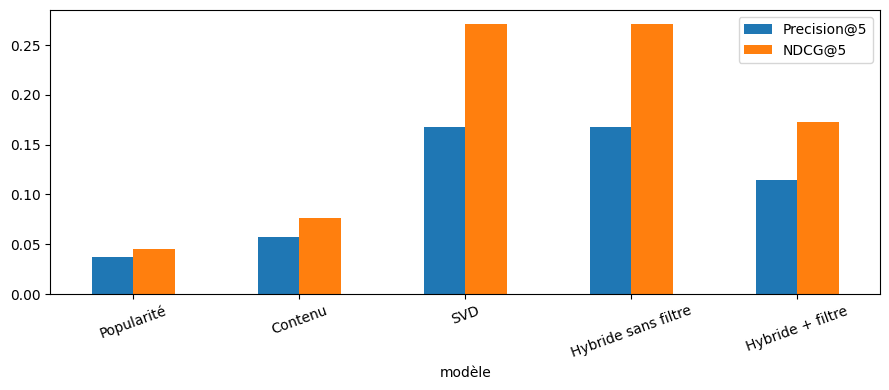

In [3]:
res.set_index('modèle')[['Precision@5', 'NDCG@5']].plot(kind='bar', figsize=(9,4)); plt.xticks(rotation=20); plt.tight_layout()
res.to_csv('../resultats.csv', index=False)